#### Phase 9 - Evaluation

Loads what `src/evaluate.py` produced (`results/evaluation/`). Nothing is retrained here.

Model choices and the threshold were fixed on validation, so the test results are not tuned. **GT crops**: digits read from perfectly cut counter crops (recognisers alone). **End to end**: raw photo through the full pipeline; a missed counter counts as wrong.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

sys.path.append(str(Path.cwd().parent / "src"))
from config import CONFIG, resolve_path
from figures import plot_digit_recognition


with open(resolve_path(CONFIG["paths"]["evaluation_summary"])) as f:
    S = json.load(f)
with open(resolve_path(CONFIG["paths"]["sensing_metrics"])) as f:
    SENS = json.load(f)

e2e = S["end_to_end_test"]
gt_fused = S["recognition_ground_truth_crops"]["testing"]["fused"]
THRESH = S["decision_ground_truth_crops"]["threshold"]

# end-to-end test predictions, one row per photo
preds = pd.read_csv(resolve_path(CONFIG["paths"]["end_to_end_predictions"]),
                    dtype={"truth": str, "fused_reading": str, **{f"{n}_reading": str for n in e2e["members"]}})
preds["confidence"] = preds["confidence"].fillna(0.0)

print("Generated:", S["generated"])
print(f"Pipeline funnel (test, {e2e['n_images']} photos)")
print(f"  Detector finds a box         : {1 - S['detection']['misses'] / S['detection']['n_images']:.1%}")
print(f"  Recognition on GT crops      : {gt_fused['full_sequence_accuracy']:.1%}")
print(f"  End to end                   : {e2e['fused']['full_sequence_accuracy']:.1%}")
print(f"  End to end, decision-approved: {e2e['decision']['approved_accuracy']:.1%}   ({e2e['decision']['approved_count']} photos approved)")

Generated: 2026-10-08 17:09:33
Pipeline funnel (test, 800 photos)
  Detector finds a box         : 99.6%
  Recognition on GT crops      : 81.4%
  End to end                   : 79.2%
  End to end, decision-approved: 95.4%   (569 photos approved)


---
### 1. Detection accuracy

Does the detector find the counter, with a box tight enough to keep every digit? Full results are in [`02_yolo_detection.ipynb`](02_yolo_detection.ipynb), section 3; both notebooks use the same detector boxes on the 800 test photos.


**Findings:** Finding the counter is not the problem: only 3 of 800 photos get no box, and 7 more have a poor box (IoU below 0.5). mAP@50-95 is lower because it rewards very tight boxes, which matters less than whether a digit gets cut off (see section 4).

---
### 2. Recognition accuracy

Given the counter, how well are the five digits read?

Tested on perfectly cut crops, so detector errors don't affect the comparison. This is not the full-system result: with the detector included, full-sequence accuracy is 79.2% (section 4).

     split   model  full-sequence (%)             per-digit d1..d5 (%)  mean per-digit (%)
validation     cnn               79.8 94.5 / 95.0 / 97.2 / 95.0 / 87.0                93.8
validation cnn_rgb               77.5 91.2 / 95.5 / 96.0 / 95.2 / 87.8                93.2
validation     svm               53.8 82.5 / 86.2 / 91.0 / 88.5 / 72.5                84.1
validation      rf               38.5 72.8 / 77.5 / 85.0 / 83.5 / 65.0                76.8
validation   fused               83.5 96.0 / 97.0 / 98.0 / 96.2 / 88.2                95.1
   testing     cnn               77.8 94.1 / 95.1 / 95.4 / 95.6 / 87.9                93.6
   testing cnn_rgb               75.6 94.4 / 94.8 / 95.2 / 95.1 / 85.0                92.9
   testing     svm               55.0 85.0 / 89.4 / 90.6 / 88.6 / 74.9                85.7
   testing      rf               40.5 79.8 / 82.1 / 84.5 / 82.8 / 67.0                79.2
   testing   fused               81.4 95.9 / 96.8 / 96.1 / 96.5 / 88.8                94.8

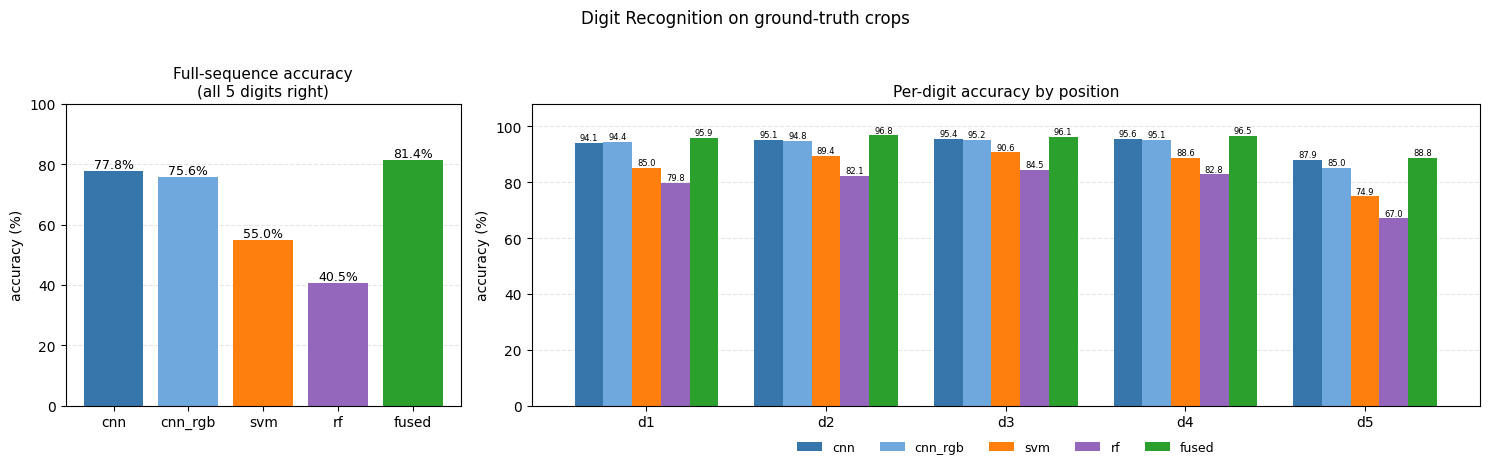

In [2]:
rows = []
for split in ("validation", "testing"):
    for name, r in S["recognition_ground_truth_crops"][split].items():
        rows.append({"split": split, "model": name, "full-sequence (%)": r["full_sequence_accuracy"] * 100,
                     "per-digit d1..d5 (%)": " / ".join(f"{x*100:.1f}" for x in r["per_digit_accuracy"]),
                     "mean per-digit (%)": float(np.mean(r["per_digit_accuracy"])) * 100})
table = pd.DataFrame(rows)
print(table.to_string(index=False, float_format=lambda x: f"{x:.1f}"))

plot_digit_recognition(S["recognition_ground_truth_crops"]["testing"])   # src/figures.py; evaluate.py saves the same figure
plt.show()

In [3]:
# One wrong digit spoils the reading, so full-sequence accuracy is below per-digit accuracy.
# "If digits failed independently" = product of the five per-digit accuracies.
acc = gt_fused["per_digit_accuracy"]
print(f"Fused mean per-digit accuracy      : {np.mean(acc):.1%}")
print(f"If digits failed independently     : {np.prod(acc):.1%}  (product of the five per-digit accuracies)")
print(f"Observed full-sequence accuracy    : {gt_fused['full_sequence_accuracy']:.1%}")
best_single = max(S['recognition_ground_truth_crops']['testing'][m]['full_sequence_accuracy'] for m in ('cnn', 'cnn_rgb', 'svm'))
print(f"Fusion gain over best single member: {(gt_fused['full_sequence_accuracy'] - best_single) * 100:+.1f} points")

Fused mean per-digit accuracy      : 94.8%
If digits failed independently     : 76.4%  (product of the five per-digit accuracies)
Observed full-sequence accuracy    : 81.4%
Fusion gain over best single member: +3.6 points


**How the "independent" figure is computed:** A reading is fully correct only if all five digits are right. If each digit succeeded on its own, the chance of all five being right is the five per-digit accuracies multiplied: 95.9% × 96.8% × 96.1% × 96.5% × 88.8% ≈ 76.4%. The real result (81.4%) is higher because errors cluster: a blurry photo tends to break several digits at once, so fewer readings are wrong.

**Findings:** The CNN is the best single model. The SVM and random forest are much weaker (the random forest is left out of the fusion). Fusing the two CNNs and the SVM adds about 3.6 points. The last digit (d5) is the hardest for every model because the drum is often half-turned.

---
### 3. Sensing / confidence accuracy

Can the system tell when it is probably wrong? Two checks help: the **decision layer** (is the model confident?) and **input sensing** (does the photo look unusual?).

#### 3a. Decision layer

Threshold choice and the confidence histograms are in `08_decision_layer.ipynb`. Here: what the threshold does end to end.

In [4]:
rows = []
for split, key in (("validation", "end_to_end_validation"), ("testing", "end_to_end_test")):
    r = S[key]["decision"]
    rows.append({"setting": f"end to end, {split}", "flag rate": r["flag_rate"], "errors caught": r["errors_caught"],
                 "approved accuracy": r["approved_accuracy"], "errors approved": r["errors_approved"]})
print(f"Threshold {THRESH:.2f}, chosen on validation\n")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.3f}"))
r = S["decision_ground_truth_crops"]["testing"]
print(f"\nFor reference, recognisers only on ground-truth crops (test): flag rate {r['flag_rate']:.3f}, "
      f"errors caught {r['errors_caught']:.3f}, approved accuracy {r['approved_accuracy']:.3f}, errors approved {r['errors_approved']}")

Threshold 0.48, chosen on validation

               setting  flag rate  errors caught  approved accuracy  errors approved
end to end, validation      0.287          0.961              0.989                3
   end to end, testing      0.289          0.843              0.954               26

For reference, recognisers only on ground-truth crops (test): flag rate 0.261, errors caught 0.866, approved accuracy 0.966, errors approved 20


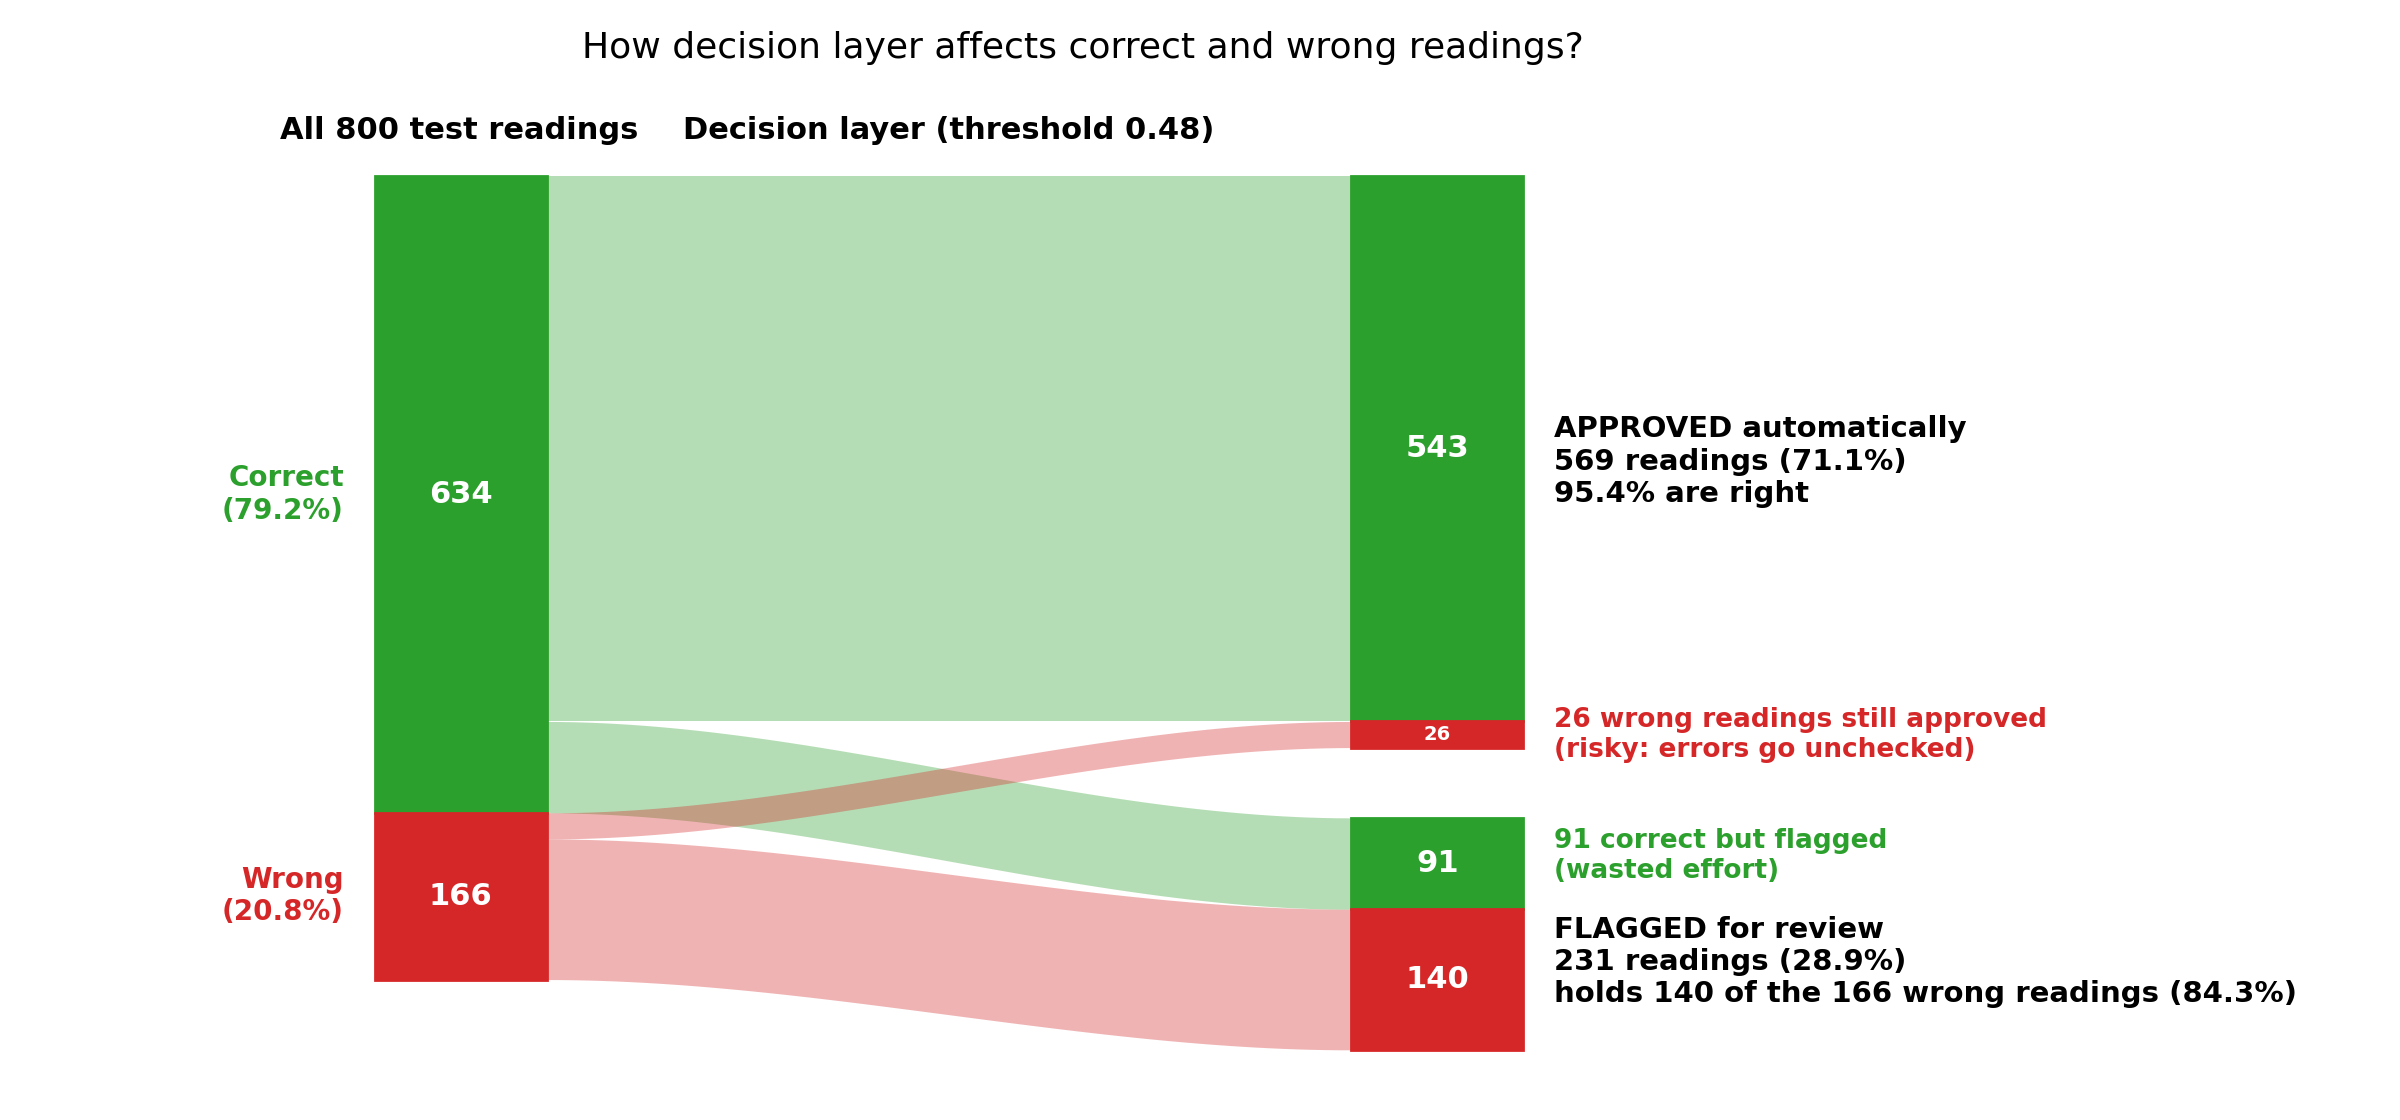

Before the layer, every reading would be trusted: 79.2% correct.
After: 569 readings are approved and 95.4% of them are correct; 231 go to a person, who now reviews 29% of the photos instead of all of them.
Errors caught: 140 of 166 wrong readings (84.3%).


In [5]:
# Flow diagram generated by 08_decision_layer.ipynb
display(Image(filename=str(resolve_path("results/decision/decision_layer_effect.png"))))

wrong = ~preds["correct"].astype(bool)
appr = preds["decision"] == "APPROVED"
print(f"Before the layer, every reading would be trusted: {e2e['fused']['full_sequence_accuracy']:.1%} correct.")
print(f"After: {int(appr.sum())} readings are approved and {preds.loc[appr, 'correct'].mean():.1%} of them are correct; "
      f"{int((~appr).sum())} go to a person, who now reviews {(~appr).mean():.0%} of the photos instead of all of them.")
print(f"Errors caught: {int((wrong & ~appr).sum())} of {int(wrong.sum())} wrong readings ({(wrong & ~appr).sum() / wrong.sum():.1%}).")

**How to read this:** Left: whether the reading is right or wrong. Right: what the decision layer did with it. A reading is *flagged* (sent to a person) when its confidence is below the threshold.
- **Wrong but approved:** errors nobody checks (the risky ones).
- **Correct but flagged:** review effort that wasn't needed.

Raising the threshold flags more readings: fewer missed errors, more wasted reviews. All numbers here are end to end, so they include detector errors, which can still look confident.

**Note:** These numbers use confidence only. The deployed app also flags photos that input sensing marks as unusual (~2%), so it flags the same readings or more.

#### 3b. Input sensing

Does it flag bad photos, and are those photos harder to read?

In [6]:
print("Flag rate on test photos:", {k: f"{v['flag_rate']:.1%}" for k, v in SENS["flag_rates"]["testing"].items()})

r = SENS["recognition_error_by_flag"]["testing"]
print(f"\nRecognition error rate, flagged crops : {r['flagged_error_rate']:.1%}  (n={r['flagged_n']})")
print(f"Recognition error rate, passed crops  : {r['passed_error_rate']:.1%}  (n={r['passed_n']})")

Flag rate on test photos: {'ground_truth_crops': '1.9%', 'detector_crops': '2.0%'}

Recognition error rate, flagged crops : 60.0%  (n=15)
Recognition error rate, passed crops  : 17.8%  (n=785)


**Findings:** Flagged photos are read wrong about 60% of the time, against 18% for the rest. But it flags only ~2% of photos, so it is a small extra safeguard, not a replacement for the confidence threshold.

---
### 4. Error analysis: what went wrong?

End-to-end test set. Each wrong reading is assigned to one cause.

166 wrong readings out of 800 (20.8%)
Detection cost: GT crops 0.8137 -> end to end 0.7925 (-0.0212)

                                          wrong  approved_anyway share of errors
1. Detector (missed or wrong region)         10                4            6.0%
2. First digit only (d1)                     20                7           12.0%
3. Last digit only (d5)                      59                8           35.5%
4. Other digits - one middle digit wrong     25                4           15.1%
5. Other digits - shifted one slot            8                1            4.8%
6. Other digits - several digits wrong       44                2           26.5%
Total                                       166               26          100.0%


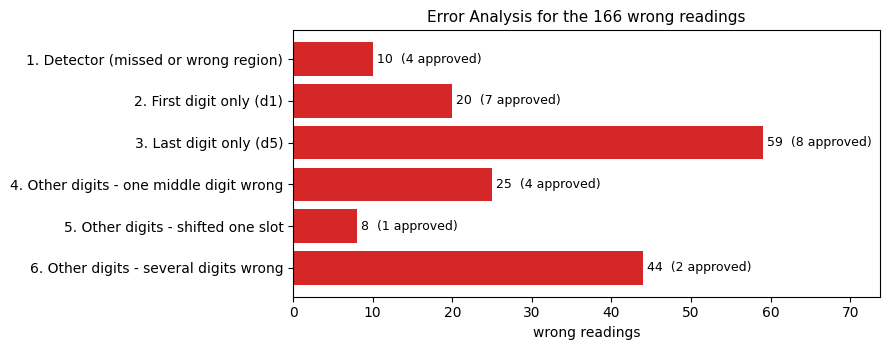

In [7]:
n_wrong = int(wrong.sum())
print(f"{n_wrong} wrong readings out of {len(preds)} ({n_wrong/len(preds):.1%})")
print(f"Detection cost: GT crops {gt_fused['full_sequence_accuracy']:.4f} -> end to end "
      f"{e2e['fused']['full_sequence_accuracy']:.4f} ({e2e['fused']['full_sequence_accuracy'] - gt_fused['full_sequence_accuracy']:+.4f})\n")

def shifted(truth, read, wrong_pos):
    """Reading is the true number moved one slot left or right (e.g. 06561 -> 05610): an offset crop."""
    if len(wrong_pos) < 2:
        return False
    for step in (1, -1):
        checks = [read[i] == truth[i + step] for i in wrong_pos if 0 <= i + step < 5]
        if len(checks) >= 2 and sum(checks) >= max(2, len(checks) - 1):
            return True
    return False

def cause(r):
    if not r["detected"] or r["iou"] < 0.5:
        return "1. Detector (missed or wrong region)"
    wrong_pos = [i for i in range(5) if r["truth"][i] != r["fused_reading"][i]]
    if wrong_pos == [0]:
        return "2. First digit only (d1)"
    if wrong_pos == [4]:
        return "3. Last digit only (d5)"
    if len(wrong_pos) == 1:
        return "4. Other digits - one middle digit wrong"
    if shifted(r["truth"], r["fused_reading"], wrong_pos):
        return "5. Other digits - shifted one slot"
    return "6. Other digits - several digits wrong"

w = preds[wrong].copy()
w["cause"] = w.apply(cause, axis=1)
tax = (w.groupby("cause").agg(wrong=("cause", "size"),
                              approved_anyway=("decision", lambda s: int((s == "APPROVED").sum()))))
tax["share of errors"] = tax["wrong"] / n_wrong
total = tax[["wrong", "approved_anyway"]].sum()
total["share of errors"] = tax["share of errors"].sum()
table = pd.concat([tax, total.to_frame("Total").T]).astype({"wrong": int, "approved_anyway": int})
table["share of errors"] = table["share of errors"].map(lambda x: f"{x:.1%}")
print(table.to_string())

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(tax.index[::-1], tax["wrong"][::-1], color="#d62728")
for i, (v, a) in enumerate(zip(tax["wrong"][::-1], tax["approved_anyway"][::-1])):
    ax.text(v + 0.5, i, f"{v}  ({a} approved)", va="center", fontsize=9)
ax.set_xlabel("wrong readings"); ax.set_title(f"Error Analysis for the {n_wrong} wrong readings", fontsize=11)
ax.set_xlim(0, tax["wrong"].max() * 1.25)
fig.tight_layout(); plt.show()

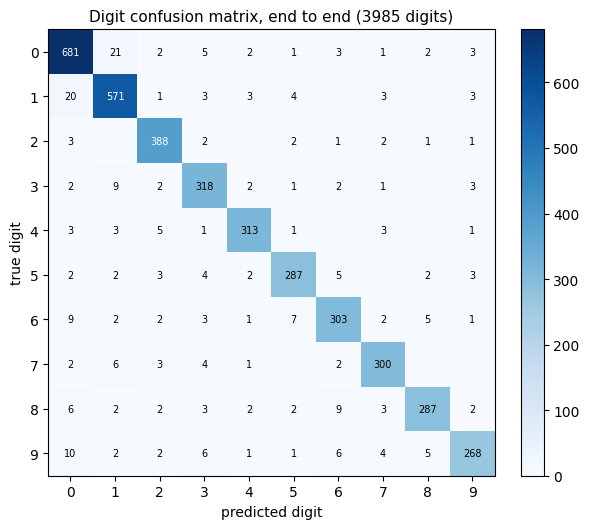

Digit accuracy end to end: 0.9325  (ground-truth crops: 0.9480)
Most frequent confusions (true -> predicted, count):
  0 -> 1: 21
  1 -> 0: 20
  9 -> 0: 10
  3 -> 1: 9
  6 -> 0: 9
  8 -> 6: 9
  6 -> 5: 7
  7 -> 1: 6
  8 -> 0: 6
  9 -> 3: 6


In [8]:
# Digit-level confusions, end to end (fused reading, test photos where the detector found a box)
det = preds[preds["detected"].astype(bool)]
cm = np.zeros((10, 10), dtype=int)
for t, r in zip(det["truth"], det["fused_reading"]):
    for a, b in zip(t, r):
        cm[int(a), int(b)] += 1
fig, ax = plt.subplots(figsize=(6.2, 5.4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit")
ax.set_title(f"Digit confusion matrix, end to end ({cm.sum()} digits)", fontsize=11)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im, ax=ax, fraction=0.046); fig.tight_layout(); plt.show()

off = [(i, j, cm[i, j]) for i in range(10) for j in range(10) if i != j and cm[i, j]]
off.sort(key=lambda x: -x[2])
print(f"Digit accuracy end to end: {np.trace(cm) / cm.sum():.4f}  (ground-truth crops: {S['confusion']['digit_accuracy']:.4f})")
print("Most frequent confusions (true -> predicted, count):")
for t, p, n_ in off[:10]:
    print(f"  {t} -> {p}: {n_}")

**Findings:** End-to-end digit accuracy is 93.3% (94.8% on GT crops). The biggest change is 0↔1 confusions, about double the GT-crop count. Of those 41, 24 are at the first digit (a clipped box leaves a sliver that looks like 0 or 1) and 11 are at the last digit (half-turned drum).

#### Silent failures: wrong readings the decision layer approved

These matter most because nobody reviews them.

26 wrong readings approved of 166 wrong in total

 basename truth fused_reading  confidence    iou                                    cause
meter1919 09174         36539      0.8938 0.0000     1. Detector (missed or wrong region)
meter1291 09305         99464      0.5128 0.0000     1. Detector (missed or wrong region)
meter1733 00001         11379      0.4901 0.0000     1. Detector (missed or wrong region)
meter1292 05633         82661      0.4820 0.0000     1. Detector (missed or wrong region)
meter1714 09404         19404      0.6475 0.9035                 2. First digit only (d1)
meter1709 04095         14095      0.6438 0.8189                 2. First digit only (d1)
meter1725 09839         19839      0.5851 0.8676                 2. First digit only (d1)
meter1438 69210         09210      0.5761 0.8957                 2. First digit only (d1)
meter1659 21696         01696      0.5337 0.8828                 2. First digit only (d1)
meter1395 18711         08711      0.5189 0.8148  

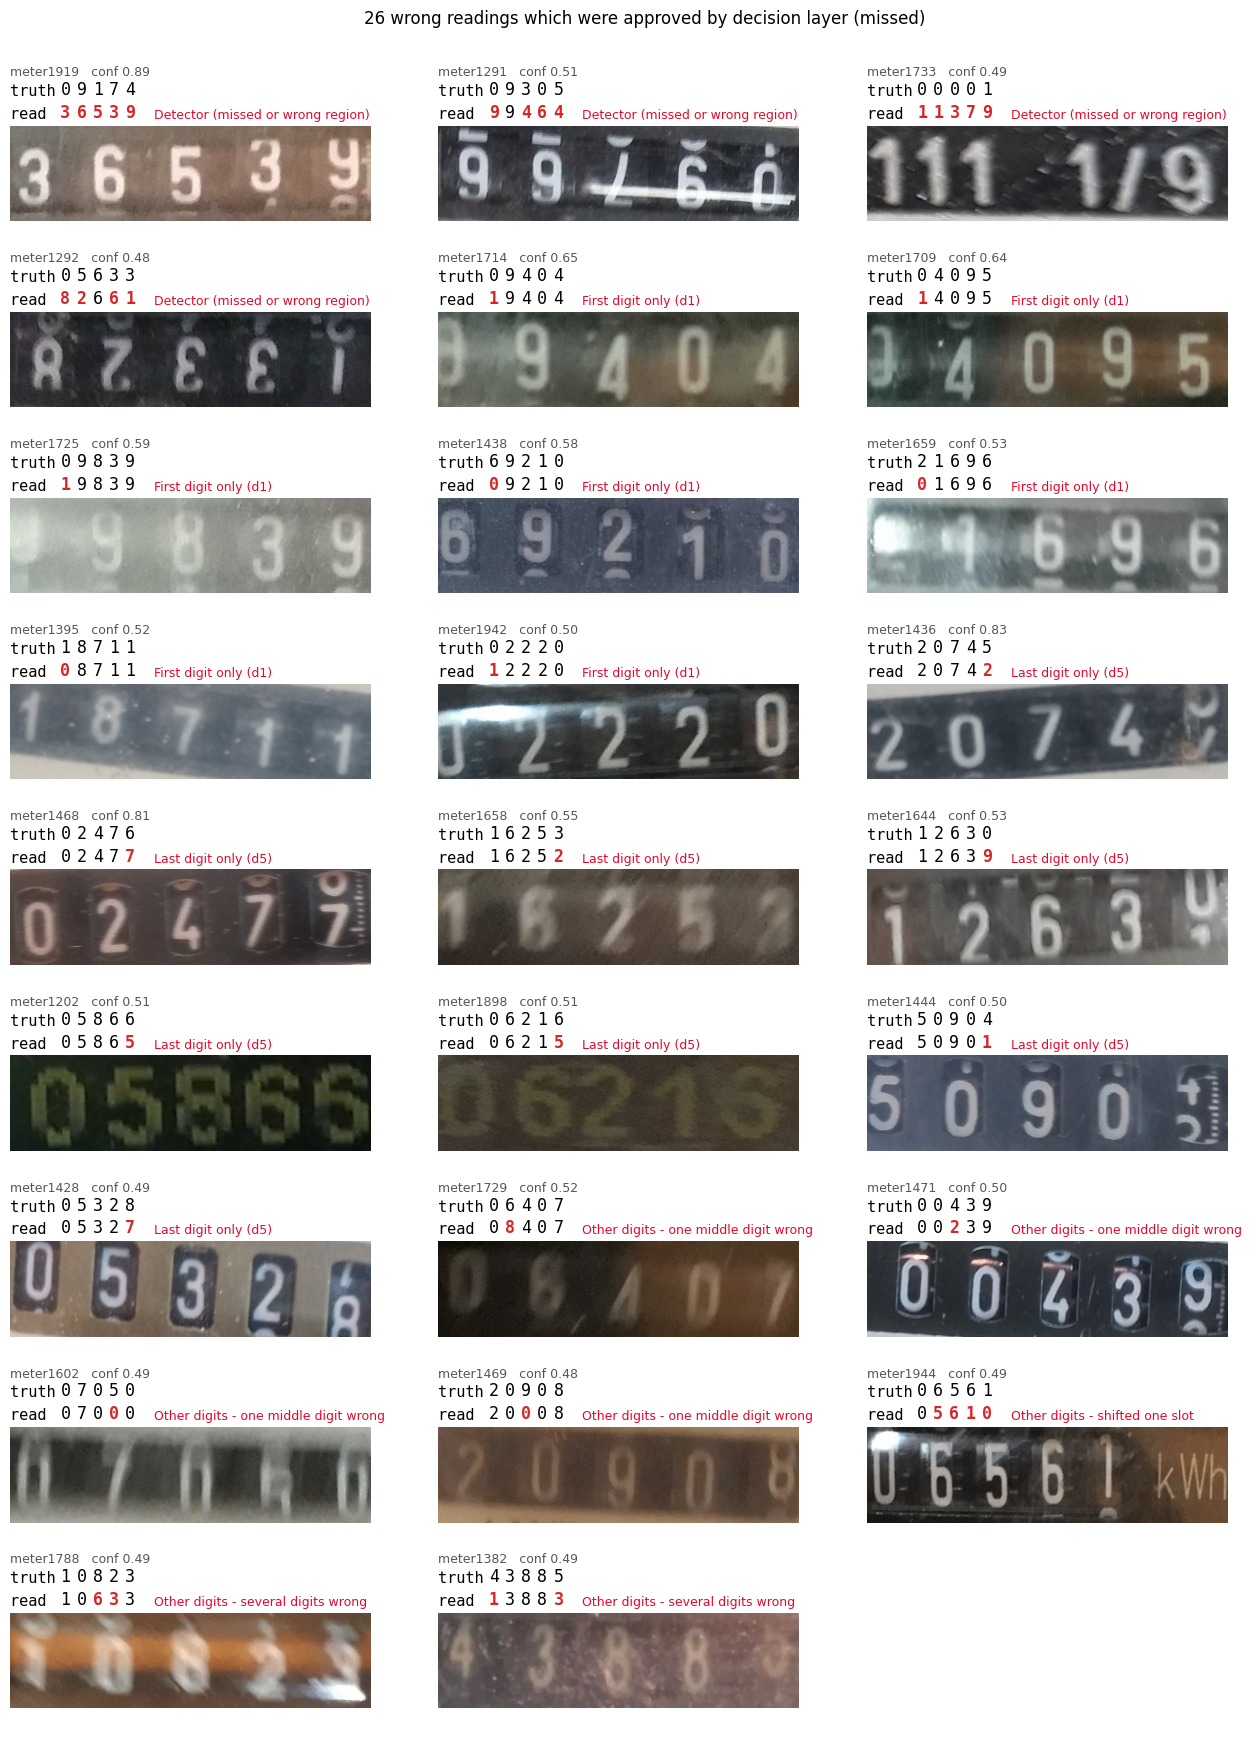

In [9]:
silent = w[w["decision"] == "APPROVED"].sort_values(["cause", "confidence"], ascending=[True, False])
print(f"{len(silent)} wrong readings approved of {n_wrong} wrong in total\n")
print(silent[["basename", "truth", "fused_reading", "confidence", "iou", "cause"]].to_string(index=False))

import cv2
from predicted_crops import predicted_crops_dir
crops_dir = predicted_crops_dir("testing")
tiles = [r for r in silent.itertuples() if (crops_dir / f"{r.basename}.jpg").exists()]
ncol = 3; nrow = -(-len(tiles) // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 1.95 * nrow))
for ax in axes.ravel():
    ax.axis("off")
for ax, r in zip(axes.ravel(), tiles):
    img = cv2.cvtColor(cv2.imread(str(crops_dir / f"{r.basename}.jpg")), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.text(0, 1.52, f"{r.basename}   conf {r.confidence:.2f}", transform=ax.transAxes, fontsize=9, color="#555555")
    for row, (label, s) in enumerate((("truth", r.truth), ("read ", r.fused_reading))):
        ax.text(0, 1.28 - row * 0.24, label, transform=ax.transAxes, fontsize=11, family="monospace", va="bottom")
        for k, ch in enumerate(s):
            bad = ch != r.truth[k]
            ax.text(0.14 + k * 0.045, 1.28 - row * 0.24, ch, transform=ax.transAxes, fontsize=12, family="monospace",
                    va="bottom", color="#d62728" if bad else "black", fontweight="bold" if bad else "normal")
    ax.text(0.40, 1.04, r.cause.split(". ", 1)[1], transform=ax.transAxes, fontsize=9, color="#e3092d", va="bottom")
fig.suptitle(f"{len(silent)} wrong readings which were approved by decision layer (missed)", y=1.0, fontsize=12)
fig.tight_layout(h_pad=0.4); plt.show()

**Findings:**
1. **Last digit off by one** (largest group): the drum is half-turned.
2. **First digit clipped by the detector box:** d1 error rises from 4.1% (GT crops) to 6.7% (end to end), the biggest rise of any digit.
3. **Detector picked the wrong region** (7 photos, 4 approved): the system confidently reads a different number. These are the most dangerous errors.
4. **Blur, glare and faded digits:** several digits fail at once.

**Ideas for next steps:** read each digit separately, handle half-turned drums, check each reading against the previous one, and try a wider crop margin (the published work uses 20%, we use 2%).

---
### 5. Benchmark

Compared with Laroca et al. 2019 on the same dataset (UFPR-AMR). Their numbers use crops from their own detector, so the fair comparison is our end-to-end row.

                                                          approach  digit accuracy (%)  full-reading accuracy (%)
             Laroca et al. – Multi-task CNN, with synthesised data               95.96                      87.69
                       Laroca et al. – CRNN, with synthesised data               97.87                      92.30
Laroca et al. – CR-NET (per-digit detector), with synthesised data               98.30                      94.13
                    MeterLens – fused, detector crops (end to end)               93.25                      79.25

Source: Laroca et al. 2019, arXiv 1902.09600, Table 7 (UFPR-AMR test split, detector-cropped counters, mean of 10 runs)


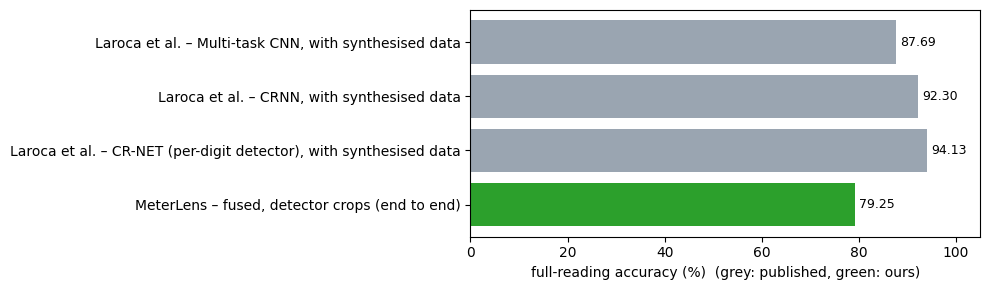

In [10]:
b = S["published_baseline"]
# Only the published methods trained with synthesised data, and our end-to-end row (the fair comparison)
rows = [{"approach": f"Laroca et al. – {r['approach']}", "digit accuracy (%)": r["digit_accuracy"], "full-reading accuracy (%)": r["full_reading_accuracy"], "who": "Laroca et al. 2019"}
        for r in b["rows"] if "synthesised" in r["approach"]]
v = b["ours"]["fused, detector crops (end to end)"]
rows.append({"approach": "MeterLens – fused, detector crops (end to end)", "digit accuracy (%)": v["digit_accuracy"], "full-reading accuracy (%)": v["full_reading_accuracy"], "who": "ours"})
bt = pd.DataFrame(rows)
print(bt.drop(columns="who").to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print("\nSource:", b["source"])

fig, ax = plt.subplots(figsize=(10, 3))
colors = ["#9aa5b1" if w_ != "ours" else "#2ca02c" for w_ in bt["who"]]
ax.barh(bt["approach"][::-1], bt["full-reading accuracy (%)"][::-1], color=colors[::-1])
for i, v in enumerate(bt["full-reading accuracy (%)"][::-1]):
    ax.text(v + 0.8, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0, 105); ax.set_xlabel("full-reading accuracy (%)  (grey: published, green: ours)")
fig.tight_layout(); plt.show()

**Findings:** Our end-to-end full-reading accuracy (79%) is below all three published methods: 88% for the multi-task CNN, 92% for the CRNN and 94% for CR-NET (one detector per digit). The gap is smaller at digit level (93% against 96–98%), because one wrong digit makes the whole reading wrong. Reading each digit separately looks like the most promising fix.

**Caveats:**
- Published numbers are the average of 10 runs; ours is a single run.
- The published detector found every counter, so no photo was missed. We count our 3 missed photos as wrong. Without them, our accuracy would be about 79.6%.
- The vision-language-model baseline was not run.

---
### 6. Summary

| Section | Key Findings |
|---|---|
| Detection | mAP@50 98.9%, mean IoU 85.5%, 3 missed photos out of 800 |
| Recognition | Fused model: 81.4% fully correct on GT crops, 94.8% of digits; the CNN is the best single model |
| Sensing / confidence | Approved readings are 95.4% correct; 29% of photos go to a person; input sensing flags ~2% of photos |
| Error analysis | Mostly last-digit (half-turned drum) errors; detector box clipping hurts the first digit |
| Benchmark | 79% end to end vs 88-94% published (single run vs 10-run average) |